# Test offline DRL using real Dataset (snapfit benchmark)

In [29]:
import pickle
import numpy as np


with open("demos/global_pose 2.pkl", 'rb') as f:
    actions= pickle.load(f)
print(actions.shape)
actions = actions[110:704-94, :]
print(actions.shape)

(704, 6)
(500, 6)


In [30]:
import numpy as np
from scipy.interpolate import interp1d

def resample_actions_with_rotation(actions, target_len):
    T, D = actions.shape

    t_old = np.linspace(0, 1, T)
    t_new = np.linspace(0, 1, target_len)

    actions_resampled = np.zeros((target_len, D))

    # ── unwrap rotation (last 3 dims) ─────────────────────────────
    actions_unwrapped = actions.copy()
    actions_unwrapped[:, 3:] = np.unwrap(actions[:, 3:], axis=0)

    # ── interpolate ──────────────────────────────────────────────
    for i in range(D):
        f = interp1d(t_old, actions_unwrapped[:, i], kind="linear")
        actions_resampled[:, i] = f(t_new)

    # ── wrap rotation back to [-π, π] ─────────────────────────────
    actions_resampled[:, 3:] = (actions_resampled[:, 3:] + np.pi) % (2 * np.pi) - np.pi

    return actions_resampled

actions_half = resample_actions_with_rotation(actions, target_len=actions.shape[0] // 4)

Raw   | min: [-0.481235 -0.164537  0.022289 -3.060396 -0.612763 -0.098674] max: [-0.45052  -0.152026  0.086541 -3.044658 -0.609281  0.051995]
Norm  | min: [-1. -1. -1. -1. -1. -1.] max: [1. 1. 1. 1. 1. 1.]


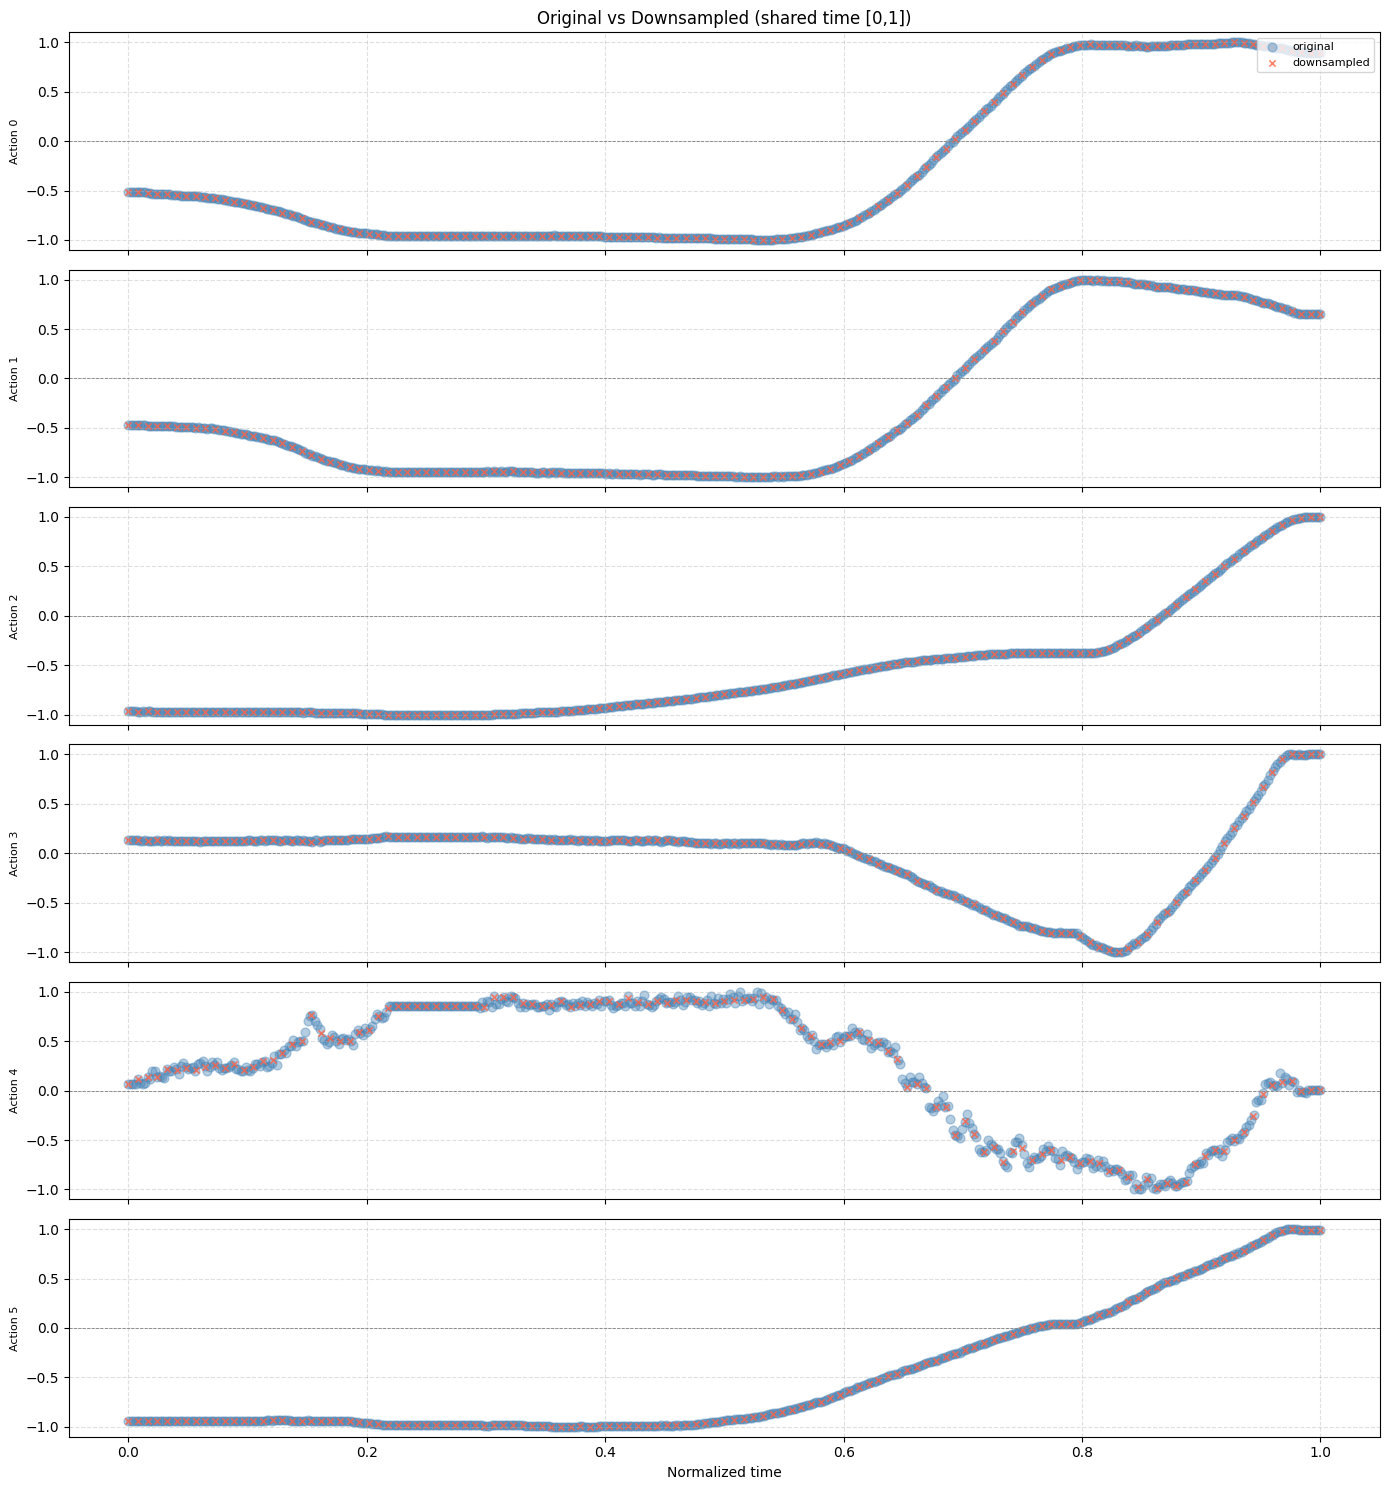

In [31]:
# from sklearn.preprocessing import MinMaxScaler
import numpy as np
import matplotlib.pyplot as plt

# ── Normalize each action dimension to [-1, 1] ───────────────────────────────
action_min = actions.min(axis=0)           # shape (7,)
action_max = actions.max(axis=0)           # shape (7,)
# action_min = np.array([-2.21e-04, -1.01e-04, -8.00e-05, -2.12e-04, -3.35e-04, -3.26e-04], dtype=np.float32)
# action_max = np.array([2.21e-04, 0.000231, 0.000796, 0.000385, 0.000279, 0.001546], dtype=np.float32)

actions_norm = 2 * (actions - action_min) / (action_max - action_min + 1e-8) - 1
actions_norm_half = 2 * (actions_half - action_min) / (action_max - action_min + 1e-8) - 1

actions_dn = (actions_norm + 1) / 2 * (action_max - action_min + 1e-8) + action_min
actions_dn_half = (actions_norm_half + 1) / 2 * (action_max - action_min + 1e-8) + action_min

# df["actions_norm"] = list(actions_norm)

print("Raw   | min:", actions.min(axis=0).round(6), "max:", actions.max(axis=0).round(6))
print("Norm  | min:", actions_norm.min(axis=0).round(3), "max:", actions_norm.max(axis=0).round(3))

fig, axes = plt.subplots(actions.shape[1], 1, figsize=(14, 2.5 * actions.shape[1]), sharex=True)

# Normalized time axes
t_orig = np.linspace(0, 1, actions.shape[0])
t_half = np.linspace(0, 1, actions_half.shape[0])

for i, ax in enumerate(axes):
    # Original — dense, small dots
    ax.scatter(t_orig, actions_norm[:, i], s=40, alpha=0.4, color="steelblue", label="original")
    # Downsampled — larger markers on top
    ax.scatter(t_half, actions_norm_half[:, i], s=20, alpha=0.8, color="tomato",
               marker="x", linewidths=1.2, label="downsampled")

    ax.set_ylabel(f"Action {i}", fontsize=8)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.6)

axes[0].legend(loc="upper right", fontsize=8)
axes[0].set_title("Original vs Downsampled (shared time [0,1])")
axes[-1].set_xlabel("Normalized time")

plt.tight_layout()
plt.show()

In [32]:
# Re-interpolate downsampled back to original length and compare
from scipy.spatial.transform import Rotation, Slerp

t_orig = np.linspace(0, 1, actions.shape[0])
t_half = np.linspace(0, 1, actions_half.shape[0])

# Upsample back — xyz
xyz_up = np.stack([np.interp(t_orig, t_half, actions_half[:, i]) for i in range(3)], axis=1)

# Upsample back — rotation via SLERP
rots_half = Rotation.from_rotvec(actions_half[:, 3:])
slerp = Slerp(t_half, rots_half)
rot_up = slerp(t_orig).as_rotvec()

actions_reconstructed = np.concatenate([xyz_up, rot_up], axis=1)

# Per-dimension MAE
mae = np.abs(actions[:, :6] - actions_reconstructed).mean(axis=0)
print("MAE per dim (should be small):", mae.round(6))

MAE per dim (should be small): [1.8e-05 1.0e-05 2.2e-05 2.4e-05 4.4e-05 9.1e-05]


In [33]:
actions = actions_half[0:125-25, :]
print(actions.shape)

(100, 6)


In [34]:

delta_actions = np.zeros_like(actions)
delta_actions[1:] = actions[1:] - actions[:-1]

# # Orientation actions (last 3): angle-aware difference, wrapped to [-π, π]
delta_actions[1:, 3:] = actions[1:, 3:] - actions[:-1, 3:]
delta_actions[1:, 3:] = (delta_actions[1:, 3:] + np.pi) % (2 * np.pi) - np.pi
print(delta_actions.shape)

# actions_subsampled = actions[::2]  # [a_0, a_2, a_4, ...]

# delta_actions = np.zeros_like(actions_subsampled)
# delta_actions[1:] = actions_subsampled[1:] - actions_subsampled[:-1]

# # # Orientation actions (last 3): angle-aware difference, wrapped to [-π, π]
# delta_actions[1:, 3:] = actions_subsampled[1:, 3:] - actions_subsampled[:-1, 3:]
# delta_actions[1:, 3:] = (delta_actions[1:, 3:] + np.pi) % (2 * np.pi) - np.pi
# # print(delta_actions.shape)
actions = delta_actions
# actions = delta_actions[100:352-2, :]
print(actions.shape)

(100, 6)
(100, 6)


Raw   | min: [-0.000553 -0.000271 -0.000161 -0.000511 -0.000492 -0.000863] max: [0.001561 0.000643 0.000763 0.000118 0.000452 0.003057]
Norm  | min: [-0.553 -0.542 -0.723 -0.051 -0.049 -0.086] max: [1.561 1.285 1.126 0.012 0.045 0.306]


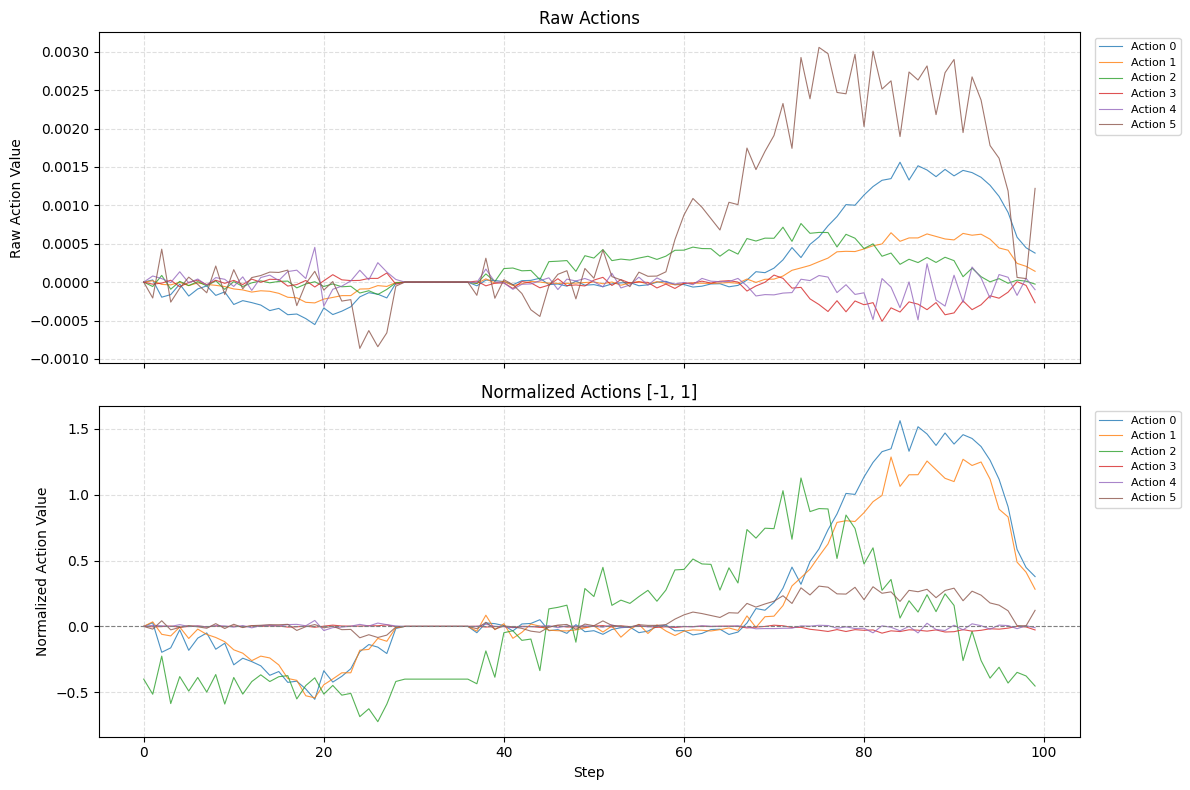

In [35]:
# from sklearn.preprocessing import MinMaxScaler
import numpy as np
import matplotlib.pyplot as plt


def _denorm(self, action_norm: np.ndarray) -> np.ndarray:
    """Map [-1,1] → original delta-pose space."""
    return (action_norm + 1) / 2 * (self.ACTION_MAX - self.ACTION_MIN + 1e-8) + self.ACTION_MIN

# ── Normalize each action dimension to [-1, 1] ───────────────────────────────
# action_min = actions.min(axis=0)           # shape (7,)
# action_max = actions.max(axis=0)           # shape (7,)

# action_min = np.array([-0.000553, -0.000271, -0.000161, -0.000511, -0.000492, -0.000863], dtype=np.float32)
# action_max = np.array([0.001561, 0.000643, 0.001263, 0.000118, 0.001452, 0.003057], dtype=np.float32)
# action_min = np.array([-0.000553*1.5, -0.000271, -0.000161*2, -0.000511, -0.000492*2, -0.000863], dtype=np.float32)
# action_max = np.array([0.001561*1.5, 0.000643, 0.000763*2, 0.000118, 0.001052*2, 0.003057], dtype=np.float32)

# Fixed action scale 
action_min = np.array([-0.001, -0.0005, -0.0003, -0.01, -0.01, -0.01], dtype=np.float32)
action_max = np.array([0.001, 0.0005, 0.0007, 0.01, 0.01, 0.01], dtype=np.float32)

actions_norm = 2 * (actions - action_min) / (action_max - action_min + 1e-8) - 1

actions_dn = (actions_norm + 1) / 2 * (action_max - action_min + 1e-8) + action_min

# df["actions_norm"] = list(actions_norm)

print("Raw   | min:", actions.min(axis=0).round(6), "max:", actions.max(axis=0).round(6))
print("Norm  | min:", actions_norm.min(axis=0).round(3), "max:", actions_norm.max(axis=0).round(3))

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

labels = [f"Action {i}" for i in range(actions.shape[1])]

x = np.arange(actions.shape[0])

# for i in range(actions.shape[1]):
#     axes[0].scatter(x, actions[:, i], s=6, alpha=0.5, label=labels[i])
#     axes[1].scatter(x, actions_norm[:, i], s=6, alpha=0.5, label=labels[i])

for i in range(actions.shape[1]): 
    axes[0].plot(actions[:, i], linewidth=0.8, alpha=0.8, label=labels[i]) 
    axes[1].plot(actions_norm[:, i], linewidth=0.8, alpha=0.8, label=labels[i])

axes[0].set_ylabel("Raw Action Value")
axes[0].set_title("Raw Actions")
axes[0].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
axes[0].grid(True, linestyle="--", alpha=0.4)
# axes[0].set_ylim(-0.5, 0.2)


axes[1].set_ylabel("Normalized Action Value")
axes[1].set_title("Normalized Actions [-1, 1]")
axes[1].axhline(y=0, color="gray", linestyle="--", linewidth=0.8)
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].set_xlabel("Step")

plt.tight_layout()
plt.show()

In [36]:
all_obs         = []
all_actions     = []


rewards_n = np.zeros((actions.shape[0], 1))
terminated_n = np.zeros((actions.shape[0], 1))
truncated_n = np.zeros((actions.shape[0], 1))
observations_n = np.zeros((actions.shape[0], 19))

ReplayBuffer = {
    "actions":            actions_norm.astype(np.float32),
    "observations":       observations_n.astype(np.float32),
    "next_observations":  observations_n.astype(np.float32),
    "rewards":            rewards_n,
    "terminated":         terminated_n,
    "truncated":          truncated_n,
}

import pandas as pd
import numpy as np

# Flatten arrays
obs = ReplayBuffer["observations"]
next_obs = ReplayBuffer["next_observations"]
actions = ReplayBuffer["actions"]
rewards = ReplayBuffer["rewards"]
terminated = ReplayBuffer["terminated"]
truncated = ReplayBuffer["truncated"]

# Convert vector fields into columns
act_df = pd.DataFrame(actions, columns=[f"actions.{i}" for i in range(actions.shape[1])])
obs_df = pd.DataFrame(obs, columns=[f"observations.{i}" for i in range(obs.shape[1])])
next_obs_df = pd.DataFrame(next_obs, columns=[f"next_observations.{i}" for i in range(next_obs.shape[1])])
rewards_df = pd.DataFrame(rewards, columns=[f"rewards.{i}" for i in range(rewards.shape[1])])
terminated_df = pd.DataFrame(terminated, columns=[f"terminated.{i}" for i in range(terminated.shape[1])])
truncated_df = pd.DataFrame(truncated, columns=[f"truncated.{i}" for i in range(truncated.shape[1])])
# rewards_df = 
# # Scalar fields
# meta_df = pd.DataFrame({
#     "reward.0": rewards,
#     "terminated.0": terminated,
#     "truncated.0": truncated
# })

# Combine everything
# df = pd.concat([act_df, obs_df, next_obs_df, meta_df], axis=1)
df = pd.concat([act_df, obs_df, next_obs_df, rewards_df, terminated_df, truncated_df], axis=1)

# Save to CSV
df.to_csv("demos/snapfit0/snapfit_fixscale.csv", index=False)

print("Replay buffer saved to demos/snapfit0/snapfit_fixscale.csv")

Replay buffer saved to demos/snapfit0/snapfit_fixscale.csv


# Pick and Insert

(1158,)
(1158, 6)
[[-0.39773156 -0.22909238  0.20905239 -3.0736514  -0.63214265  0.05566178]
 [-0.39771706 -0.22909813  0.20903485 -3.07363401 -0.63213165  0.05559295]
 [-0.39772248 -0.22908085  0.20903232 -3.07365374 -0.63209142  0.05561113]
 [-0.39769516 -0.22909775  0.20901489 -3.07363267 -0.63212447  0.05552355]
 [-0.39769297 -0.22911026  0.20902212 -3.07363867 -0.63217201  0.05555309]]
(1158, 6)
Raw   | min: [-0.398225 -0.232875  0.068989 -3.073713 -0.632273  0.035969] max: [-0.383096 -0.228095  0.209063 -3.054583 -0.624058  0.056853]
Norm  | min: [-1. -1. -1. -1. -1. -1.] max: [1. 1. 1. 1. 1. 1.]


Text(0.5, 0, 'Step')

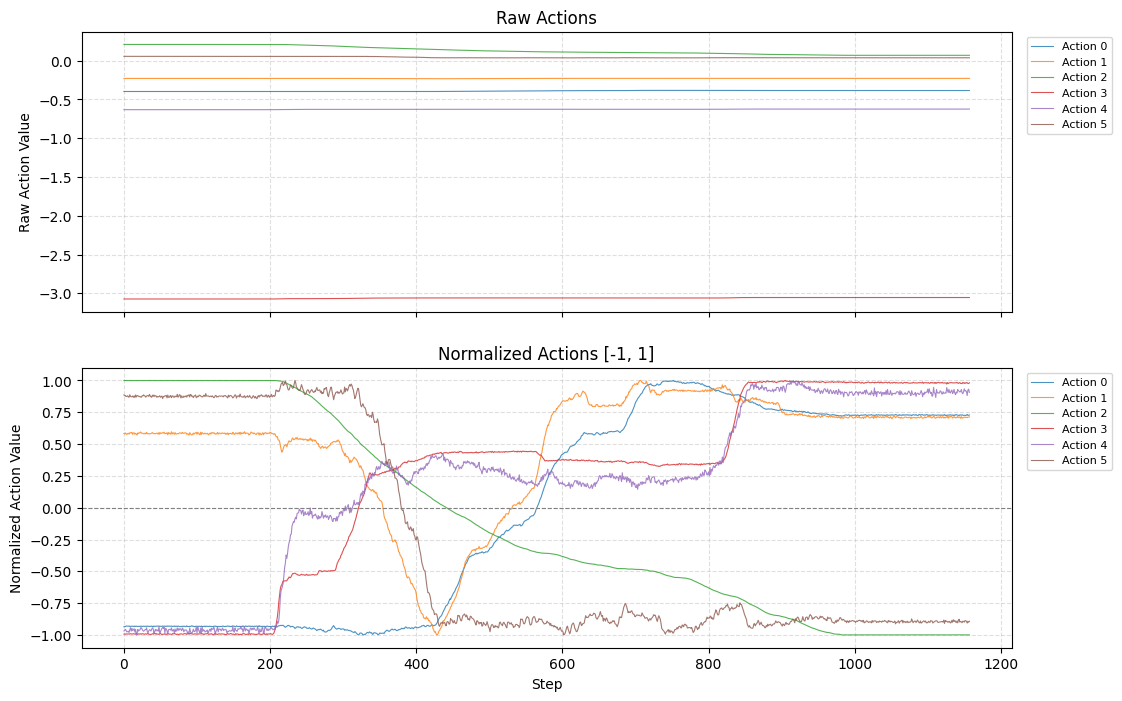

In [4]:
import pickle
import numpy as np
# from sklearn.preprocessing import MinMaxScaler
import numpy as np
import matplotlib.pyplot as plt

with open("demos/Peginhole/rel_trajectory 11.pkl", 'rb') as f:
    pp= pickle.load(f)
# print(gripper)
# Convert the extracted list directly into a NumPy array
gripper = np.array([item[1] for item in pp])

print(gripper.shape) # (352,)

with open("demos/Peginhole/global_pose 11.pkl", 'rb') as f:
    actions= pickle.load(f)
print(actions.shape) # (352,6)

print(actions[:5, :])  # Print the first 5 rows of actions for verification

# # delta_actions = np.zeros_like(actions)
# delta_actions[1:] = actions[1:] - actions[:-1]

# # # # # Orientation actions (last 3): angle-aware difference, wrapped to [-π, π]
# # # delta_actions[1:, 3:] = actions[1:, 3:] - actions[:-1, 3:]
# delta_actions[1:, 3:] = (actions[1:, 3:] - actions[:-1, 3:] + np.pi) % (2 * np.pi) - np.pi
# # delta = (current_angle - last_angle + np.pi) % (2 * np.pi) - np.pi
# # # print(delta_actions.shape)
# # Detect episode boundaries and zero out deltas at resets
# reset_mask = np.abs(delta_actions) > 0.05   # e.g. threshold = 0.5
# delta_actions[reset_mask] = 0.0

# # actions_subsampled = actions[::2]  # [a_0, a_2, a_4, ...]

# # delta_actions = np.zeros_like(actions_subsampled)
# # delta_actions[1:] = actions_subsampled[1:] - actions_subsampled[:-1]

# # # # Orientation actions (last 3): angle-aware difference, wrapped to [-π, π]
# # delta_actions[1:, 3:] = actions_subsampled[1:, 3:] - actions_subsampled[:-1, 3:]
# # delta_actions[1:, 3:] = (delta_actions[1:, 3:] + np.pi) % (2 * np.pi) - np.pi
# # # print(delta_actions.shape)

# actions = delta_actions

# # actions = delta_actions[100:352-2, :]
# reshape gripper to (352, 1)
gripper = gripper.reshape(-1, 1)

# # append as new column
# actions = np.concatenate([actions, gripper], axis=1)

print(actions.shape)
# print(actions.shape)

def _denorm(self, action_norm: np.ndarray) -> np.ndarray:
    """Map [-1,1] → original delta-pose space."""
    return (action_norm + 1) / 2 * (self.ACTION_MAX - self.ACTION_MIN + 1e-8) + self.ACTION_MIN

# ── Normalize each action dimension to [-1, 1] ───────────────────────────────
action_min = actions.min(axis=0)           # shape (7,)
action_max = actions.max(axis=0)           # shape (7,)

actions_norm = 2 * (actions - action_min) / (action_max - action_min + 1e-8) - 1

actions_dn = (actions_norm + 1) / 2 * (action_max - action_min + 1e-8) + action_min

# df["actions_norm"] = list(actions_norm)

print("Raw   | min:", actions.min(axis=0).round(6), "max:", actions.max(axis=0).round(6))
print("Norm  | min:", actions_norm.min(axis=0).round(3), "max:", actions_norm.max(axis=0).round(3))

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

labels = [f"Action {i}" for i in range(actions.shape[1])]

x = np.arange(actions.shape[0])

# for i in range(actions.shape[1]):
#     axes[0].scatter(x, actions[:, i], s=6, alpha=0.5, label=labels[i])
#     axes[1].scatter(x, actions_norm[:, i], s=6, alpha=0.5, label=labels[i])

for i in range(actions.shape[1]): 
    axes[0].plot(actions[:, i], linewidth=0.8, alpha=0.8, label=labels[i]) 
    axes[1].plot(actions_norm[:, i], linewidth=0.8, alpha=0.8, label=labels[i])

axes[0].set_ylabel("Raw Action Value")
axes[0].set_title("Raw Actions")
axes[0].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
axes[0].grid(True, linestyle="--", alpha=0.4)
# axes[0].set_ylim(-0.5, 0.2)


axes[1].set_ylabel("Normalized Action Value")
axes[1].set_title("Normalized Actions [-1, 1]")
axes[1].axhline(y=0, color="gray", linestyle="--", linewidth=0.8)
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].set_xlabel("Step")


In [6]:
import numpy as np
from scipy.interpolate import interp1d

import numpy as np
from scipy.interpolate import interp1d


def resample_actions_with_rotation(actions, target_len):
    T, D = actions.shape

    t_old = np.linspace(0, 1, T)
    t_new = np.linspace(0, 1, target_len)

    actions_resampled = np.zeros((target_len, D))

    # ── unwrap rotation (last 3 dims) ─────────────────────────────
    actions_unwrapped = actions.copy()
    actions_unwrapped[:, 3:] = np.unwrap(actions[:, 3:], axis=0)

    # ── interpolate ──────────────────────────────────────────────
    for i in range(D):
        f = interp1d(t_old, actions_unwrapped[:, i], kind="linear")
        actions_resampled[:, i] = f(t_new)

    # ── wrap rotation back to [-π, π] ─────────────────────────────
    actions_resampled[:, 3:] = (actions_resampled[:, 3:] + np.pi) % (2 * np.pi) - np.pi

    return actions_resampled

actions_half = resample_actions_with_rotation(actions, target_len=actions.shape[0] // 4)

Raw   | min: [-0.398225 -0.232875  0.068989 -3.073713 -0.632273  0.035969] max: [-0.383096 -0.228095  0.209063 -3.054583 -0.624058  0.056853]
Norm  | min: [-1.002 -1.011 -1.    -1.002 -1.013 -1.003] max: [1.002 1.    1.    1.004 1.001 1.006]


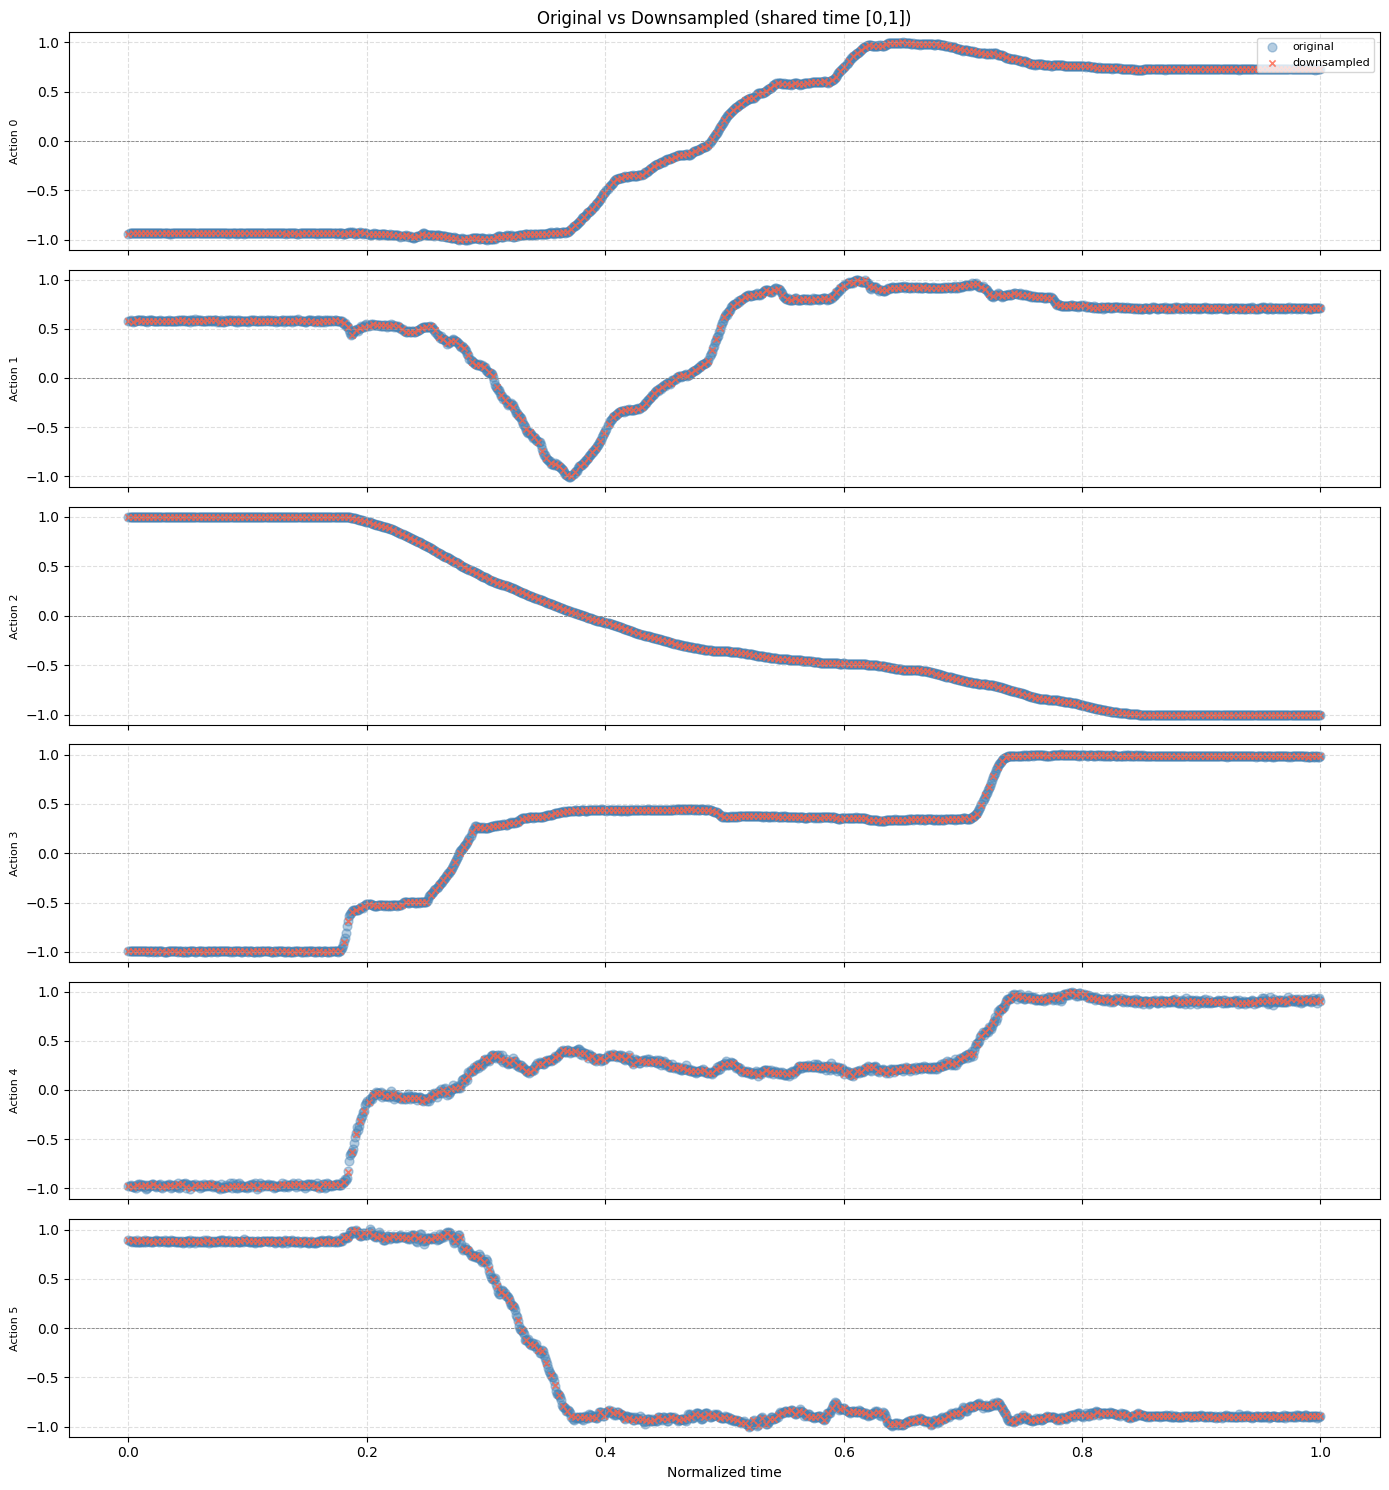

In [7]:
# from sklearn.preprocessing import MinMaxScaler
import numpy as np
import matplotlib.pyplot as plt

# ── Normalize each action dimension to [-1, 1] ───────────────────────────────
action_min = actions_half.min(axis=0)           # shape (7,)
action_max = actions_half.max(axis=0)           # shape (7,)
# action_min = np.array([-2.21e-04, -1.01e-04, -8.00e-05, -2.12e-04, -3.35e-04, -3.26e-04], dtype=np.float32)
# action_max = np.array([2.21e-04, 0.000231, 0.000796, 0.000385, 0.000279, 0.001546], dtype=np.float32)

actions_norm = 2 * (actions - action_min) / (action_max - action_min + 1e-8) - 1
actions_norm_half = 2 * (actions_half - action_min) / (action_max - action_min + 1e-8) - 1

actions_dn = (actions_norm + 1) / 2 * (action_max - action_min + 1e-8) + action_min
actions_dn_half = (actions_norm_half + 1) / 2 * (action_max - action_min + 1e-8) + action_min

# df["actions_norm"] = list(actions_norm)

print("Raw   | min:", actions.min(axis=0).round(6), "max:", actions.max(axis=0).round(6))
print("Norm  | min:", actions_norm.min(axis=0).round(3), "max:", actions_norm.max(axis=0).round(3))

fig, axes = plt.subplots(actions.shape[1], 1, figsize=(14, 2.5 * actions.shape[1]), sharex=True)

# Normalized time axes
t_orig = np.linspace(0, 1, actions.shape[0])
t_half = np.linspace(0, 1, actions_half.shape[0])

for i, ax in enumerate(axes):
    # Original — dense, small dots
    ax.scatter(t_orig, actions_norm[:, i], s=40, alpha=0.4, color="steelblue", label="original")
    # Downsampled — larger markers on top
    ax.scatter(t_half, actions_norm_half[:, i], s=20, alpha=0.8, color="tomato",
               marker="x", linewidths=1.2, label="downsampled")

    ax.set_ylabel(f"Action {i}", fontsize=8)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.6)

axes[0].legend(loc="upper right", fontsize=8)
axes[0].set_title("Original vs Downsampled (shared time [0,1])")
axes[-1].set_xlabel("Normalized time")

plt.tight_layout()
plt.show()

/tmp/ipykernel_2314770/409561046.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)


Text(0.5, 0, 'Step')

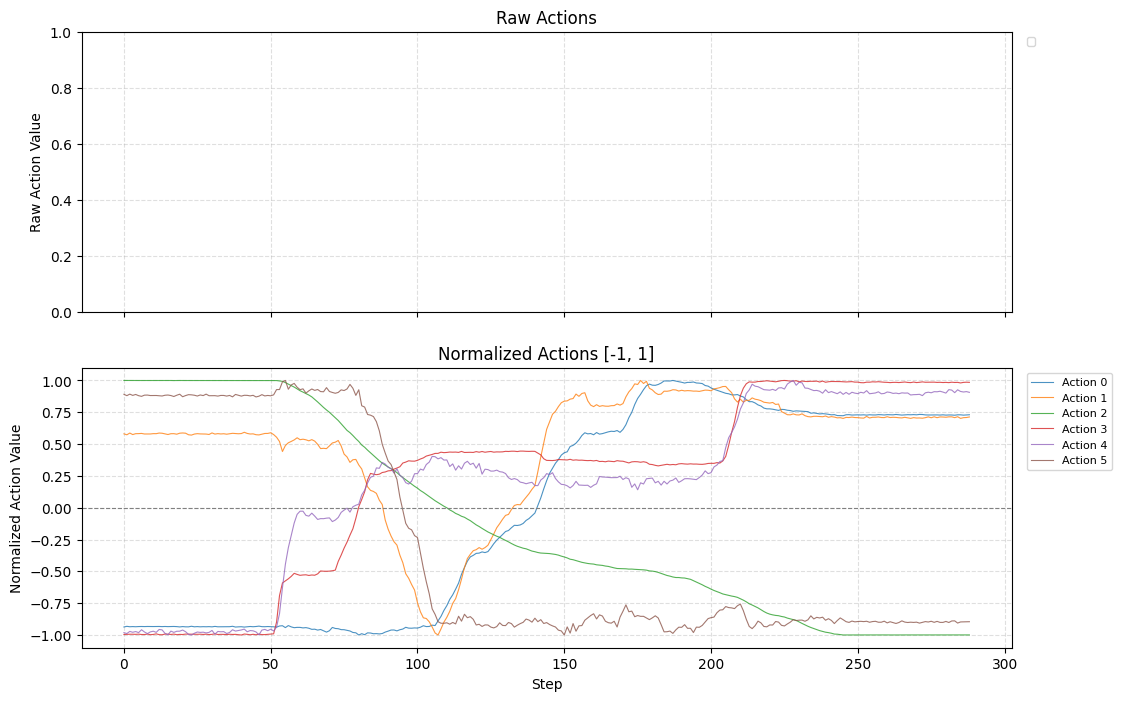

In [8]:
# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

labels = [f"Action {i}" for i in range(actions.shape[1])]

x = np.arange(actions.shape[0])

# for i in range(actions.shape[1]):
#     axes[0].scatter(x, actions[:, i], s=6, alpha=0.5, label=labels[i])
#     axes[1].scatter(x, actions_norm[:, i], s=6, alpha=0.5, label=labels[i])

for i in range(actions.shape[1]): 
    # axes[0].plot(actions[:, i], linewidth=0.8, alpha=0.8, label=labels[i]) 
    axes[1].plot(actions_norm_half[:, i], linewidth=0.8, alpha=0.8, label=labels[i])

axes[0].set_ylabel("Raw Action Value")
axes[0].set_title("Raw Actions")
axes[0].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
axes[0].grid(True, linestyle="--", alpha=0.4)
# axes[0].set_ylim(-0.5, 0.2)


axes[1].set_ylabel("Normalized Action Value")
axes[1].set_title("Normalized Actions [-1, 1]")
axes[1].axhline(y=0, color="gray", linestyle="--", linewidth=0.8)
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].set_xlabel("Step")

In [9]:
print(actions_norm_half.shape)
actions_norm = actions_norm_half[160:260,:]
print(actions_norm.shape)
print(actions_half.shape)
print(actions_norm[:5, :])

(289, 6)
(100, 6)
(289, 6)
[[ 0.57326034  0.79420065 -0.44282426  0.36789461  0.17659554 -0.83299127]
 [ 0.59059378  0.80967249 -0.44850327  0.37150282  0.18782494 -0.87385256]
 [ 0.57826099  0.79615371 -0.45087686  0.36313739  0.24551385 -0.84167956]
 [ 0.58231465  0.80181253 -0.45322923  0.36425302  0.24141448 -0.85126419]
 [ 0.58900723  0.79803537 -0.45817471  0.36109343  0.2402512  -0.89166042]]


In [10]:
print(actions_half.shape)
print(actions_half[160:205, :])

(289, 6)
[[-0.38633344 -0.22858439  0.10802976 -3.06064544 -0.6274192   0.03773944]
 [-0.38620263 -0.22854761  0.10763213 -3.06061103 -0.6273734   0.03731464]
 [-0.38629571 -0.22857975  0.10746593 -3.0606908  -0.62713809  0.03764911]
 [-0.38626511 -0.22856629  0.10730123 -3.06068016 -0.62715481  0.03754947]
 [-0.38621461 -0.22857527  0.10695496 -3.0607103  -0.62715956  0.0371295 ]
 [-0.38616118 -0.22857704  0.10674962 -3.06066147 -0.62716825  0.03700891]
 [-0.38612536 -0.22856673  0.10634366 -3.06068443 -0.62717611  0.03696895]
 [-0.38613875 -0.22856471  0.10593694 -3.06070209 -0.62717449  0.03712581]
 [-0.38608287 -0.22853423  0.10560155 -3.06062864 -0.62717295  0.03665517]
 [-0.38619009 -0.22855571  0.1055543  -3.06066043 -0.62713041  0.03746395]
 [-0.38601704 -0.22852737  0.10551511 -3.06067085 -0.62723496  0.03794391]
 [-0.38573731 -0.22840141  0.10543489 -3.06073693 -0.62717828  0.0384654 ]
 [-0.38532157 -0.22830848  0.10526326 -3.0607975  -0.6272157   0.03790175]
 [-0.3850012  -0

In [11]:
all_obs         = []
all_actions     = []


rewards_n = np.zeros((actions.shape[0], 1))
terminated_n = np.zeros((actions.shape[0], 1))
truncated_n = np.zeros((actions.shape[0], 1))
observations_n = np.zeros((actions.shape[0], 19))

ReplayBuffer = {
    "actions":            actions_norm.astype(np.float32),
    "observations":       observations_n.astype(np.float32),
    "next_observations":  observations_n.astype(np.float32),
    "rewards":            rewards_n,
    "terminated":         terminated_n,
    "truncated":          truncated_n,
}

import pandas as pd
import numpy as np

# Flatten arrays
obs = ReplayBuffer["observations"]
next_obs = ReplayBuffer["next_observations"]
actions = ReplayBuffer["actions"]
rewards = ReplayBuffer["rewards"]
terminated = ReplayBuffer["terminated"]
truncated = ReplayBuffer["truncated"]

# Convert vector fields into columns
act_df = pd.DataFrame(actions, columns=[f"actions.{i}" for i in range(actions.shape[1])])
obs_df = pd.DataFrame(obs, columns=[f"observations.{i}" for i in range(obs.shape[1])])
next_obs_df = pd.DataFrame(next_obs, columns=[f"next_observations.{i}" for i in range(next_obs.shape[1])])
rewards_df = pd.DataFrame(rewards, columns=[f"rewards.{i}" for i in range(rewards.shape[1])])
terminated_df = pd.DataFrame(terminated, columns=[f"terminated.{i}" for i in range(terminated.shape[1])])
truncated_df = pd.DataFrame(truncated, columns=[f"truncated.{i}" for i in range(truncated.shape[1])])
# rewards_df = 
# # Scalar fields
# meta_df = pd.DataFrame({
#     "reward.0": rewards,
#     "terminated.0": terminated,
#     "truncated.0": truncated
# })

# Combine everything
# df = pd.concat([act_df, obs_df, next_obs_df, meta_df], axis=1)
df = pd.concat([act_df, obs_df, next_obs_df, rewards_df, terminated_df, truncated_df], axis=1)

# Save to CSV
df.to_csv("demos/assemble/assembly_gripper.csv", index=False)

print("Replay buffer saved to demos/assemble/assembly_gripper.csv")

Replay buffer saved to demos/assemble/assembly_gripper.csv


In [12]:
actions = actions_half

In [13]:
delta_actions = np.zeros_like(actions)
delta_actions[1:] = actions[1:] - actions[:-1]

# # # # Orientation actions (last 3): angle-aware difference, wrapped to [-π, π]
# # delta_actions[1:, 3:] = actions[1:, 3:] - actions[:-1, 3:]
delta_actions[1:, 3:] = (actions[1:, 3:] - actions[:-1, 3:] + np.pi) % (2 * np.pi) - np.pi
# delta = (current_angle - last_angle + np.pi) % (2 * np.pi) - np.pi
# # print(delta_actions.shape)
# Detect episode boundaries and zero out deltas at resets
reset_mask = np.abs(delta_actions) > 0.05   # e.g. threshold = 0.5
delta_actions[reset_mask] = 0.0

# # actions_subsampled = actions[::2]  # [a_0, a_2, a_4, ...]

# # delta_actions = np.zeros_like(actions_subsampled)
# # delta_actions[1:] = actions_subsampled[1:] - actions_subsampled[:-1]

# # # # Orientation actions (last 3): angle-aware difference, wrapped to [-π, π]
# # delta_actions[1:, 3:] = actions_subsampled[1:, 3:] - actions_subsampled[:-1, 3:]
# # delta_actions[1:, 3:] = (delta_actions[1:, 3:] + np.pi) % (2 * np.pi) - np.pi
# # # print(delta_actions.shape)

actions = delta_actions

# # actions = delta_actions[100:352-2, :]
# reshape gripper to (352, 1)
# gripper = gripper.reshape(-1, 1)

# append as new column
# actions = np.concatenate([actions, gripper], axis=1)

In [14]:
print(actions.shape)

(289, 6)


In [15]:
actions = actions[160:260,:]
print(actions.shape)

(100, 6)


Raw   | min: [-0.000161 -0.000142 -0.001064 -0.00014  -0.000269 -0.000705] max: [4.600e-04 1.260e-04 2.800e-05 1.067e-03 4.170e-04 8.090e-04]
Norm  | min: [-0.305 -0.378 -0.65  -0.131 -0.646 -0.555] max: [0.87  0.336 0.966 1.    1.    0.637]


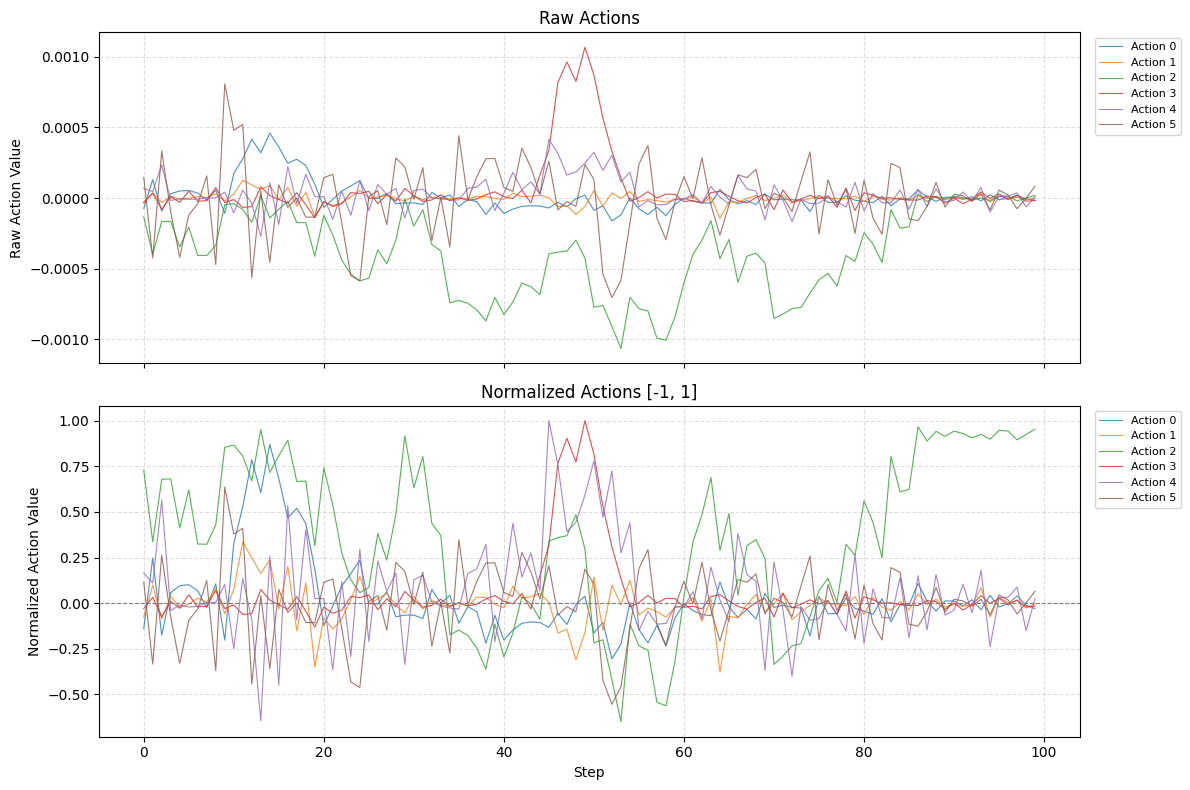

In [16]:
# from sklearn.preprocessing import MinMaxScaler
import numpy as np
import matplotlib.pyplot as plt


def _denorm(self, action_norm: np.ndarray) -> np.ndarray:
    """Map [-1,1] → original delta-pose space."""
    return (action_norm + 1) / 2 * (self.ACTION_MAX - self.ACTION_MIN + 1e-8) + self.ACTION_MIN

# # ── Normalize each action dimension to [-1, 1] ───────────────────────────────
# action_min = actions.min(axis=0)           # shape (7,)
# action_max = actions.max(axis=0)           # shape (7,)

action_min = np.array([[-5.290e-04, -3.750e-04, -0.001301, -1.067e-03,  -4.170e-04, -0.00127 ]], dtype=np.float32)
action_max = np.array([[5.290e-04, 3.750e-04, 0.000051, 1.067e-03,  4.170e-04, 0.00127 ]], dtype=np.float32) # [5.290e-04 2.750e-04 2.800e-05 1.067e-03 4.170e-04 8.090e-04]
# action_min = np.array([-0.000553*1.5, -0.000271, -0.000161*2, -0.000511, -0.000492*2, -0.000863], dtype=np.float32)
# action_max = np.array([0.001561*1.5, 0.000643, 0.000763*2, 0.000118, 0.001052*2, 0.003057], dtype=np.float32)


actions_norm = 2 * (actions - action_min) / (action_max - action_min + 1e-8) - 1

actions_dn = (actions_norm + 1) / 2 * (action_max - action_min + 1e-8) + action_min

# df["actions_norm"] = list(actions_norm)

print("Raw   | min:", actions.min(axis=0).round(6), "max:", actions.max(axis=0).round(6))
print("Norm  | min:", actions_norm.min(axis=0).round(3), "max:", actions_norm.max(axis=0).round(3))

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

labels = [f"Action {i}" for i in range(actions.shape[1])]

x = np.arange(actions.shape[0])

# for i in range(actions.shape[1]):
#     axes[0].scatter(x, actions[:, i], s=6, alpha=0.5, label=labels[i])
#     axes[1].scatter(x, actions_norm[:, i], s=6, alpha=0.5, label=labels[i])

for i in range(actions.shape[1]): 
    axes[0].plot(actions[:, i], linewidth=0.8, alpha=0.8, label=labels[i]) 
    axes[1].plot(actions_norm[:, i], linewidth=0.8, alpha=0.8, label=labels[i])

axes[0].set_ylabel("Raw Action Value")
axes[0].set_title("Raw Actions")
axes[0].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
axes[0].grid(True, linestyle="--", alpha=0.4)
# axes[0].set_ylim(-0.5, 0.2)


axes[1].set_ylabel("Normalized Action Value")
axes[1].set_title("Normalized Actions [-1, 1]")
axes[1].axhline(y=0, color="gray", linestyle="--", linewidth=0.8)
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].set_xlabel("Step")

plt.tight_layout()
plt.show()

In [17]:
print(actions_norm[:,0:6].shape)

(100, 6)


In [18]:
all_obs         = []
all_actions     = []


rewards_n = np.zeros((actions.shape[0], 1))
terminated_n = np.zeros((actions.shape[0], 1))
truncated_n = np.zeros((actions.shape[0], 1))
observations_n = np.zeros((actions.shape[0], 18))

ReplayBuffer = {
    "actions":            actions_norm[:,0:6].astype(np.float32),
    "observations":       observations_n.astype(np.float32),
    "next_observations":  observations_n.astype(np.float32),
    "rewards":            rewards_n,
    "terminated":         terminated_n,
    "truncated":          truncated_n,
}

import pandas as pd
import numpy as np

# Flatten arrays
obs = ReplayBuffer["observations"]
next_obs = ReplayBuffer["next_observations"]
actions = ReplayBuffer["actions"]
rewards = ReplayBuffer["rewards"]
terminated = ReplayBuffer["terminated"]
truncated = ReplayBuffer["truncated"]

# Convert vector fields into columns
act_df = pd.DataFrame(actions, columns=[f"actions.{i}" for i in range(actions.shape[1])])
obs_df = pd.DataFrame(obs, columns=[f"observations.{i}" for i in range(obs.shape[1])])
next_obs_df = pd.DataFrame(next_obs, columns=[f"next_observations.{i}" for i in range(next_obs.shape[1])])
rewards_df = pd.DataFrame(rewards, columns=[f"rewards.{i}" for i in range(rewards.shape[1])])
terminated_df = pd.DataFrame(terminated, columns=[f"terminated.{i}" for i in range(terminated.shape[1])])
truncated_df = pd.DataFrame(truncated, columns=[f"truncated.{i}" for i in range(truncated.shape[1])])
# rewards_df = 
# # Scalar fields
# meta_df = pd.DataFrame({
#     "reward.0": rewards,
#     "terminated.0": terminated,
#     "truncated.0": truncated
# })

# Combine everything
# df = pd.concat([act_df, obs_df, next_obs_df, meta_df], axis=1)
df = pd.concat([act_df, obs_df, next_obs_df, rewards_df, terminated_df, truncated_df], axis=1)

# Save to CSV
df.to_csv("demos/Peginhole/assembly.csv", index=False)

print("Replay buffer saved to demos/Peginhole/assembly.csv")

Replay buffer saved to demos/Peginhole/assembly.csv


In [108]:
all_obs         = []
all_actions     = []


rewards_n = np.zeros((actions.shape[0], 1))
terminated_n = np.zeros((actions.shape[0], 1))
truncated_n = np.zeros((actions.shape[0], 1))
observations_n = np.zeros((actions.shape[0], 19))

ReplayBuffer = {
    "actions":            actions_norm.astype(np.float32),
    "observations":       observations_n.astype(np.float32),
    "next_observations":  observations_n.astype(np.float32),
    "rewards":            rewards_n,
    "terminated":         terminated_n,
    "truncated":          truncated_n,
}

import pandas as pd
import numpy as np

# Flatten arrays
obs = ReplayBuffer["observations"]
next_obs = ReplayBuffer["next_observations"]
actions = ReplayBuffer["actions"]
rewards = ReplayBuffer["rewards"]
terminated = ReplayBuffer["terminated"]
truncated = ReplayBuffer["truncated"]

# Convert vector fields into columns
act_df = pd.DataFrame(actions, columns=[f"actions.{i}" for i in range(actions.shape[1])])
obs_df = pd.DataFrame(obs, columns=[f"observations.{i}" for i in range(obs.shape[1])])
next_obs_df = pd.DataFrame(next_obs, columns=[f"next_observations.{i}" for i in range(next_obs.shape[1])])
rewards_df = pd.DataFrame(rewards, columns=[f"rewards.{i}" for i in range(rewards.shape[1])])
terminated_df = pd.DataFrame(terminated, columns=[f"terminated.{i}" for i in range(terminated.shape[1])])
truncated_df = pd.DataFrame(truncated, columns=[f"truncated.{i}" for i in range(truncated.shape[1])])
# rewards_df = 
# # Scalar fields
# meta_df = pd.DataFrame({
#     "reward.0": rewards,
#     "terminated.0": terminated,
#     "truncated.0": truncated
# })

# Combine everything
# df = pd.concat([act_df, obs_df, next_obs_df, meta_df], axis=1)
df = pd.concat([act_df, obs_df, next_obs_df, rewards_df, terminated_df, truncated_df], axis=1)

# Save to CSV
df.to_csv("demos/assemble/pick_gripper.csv", index=False)

print("Replay buffer saved to demos/assemble/pick_gripper.csv")

Replay buffer saved to demos/assemble/pick_gripper.csv


In [1]:
import pandas as pd

# Read the CSV file
df = pd.read_csv('demos/snapfit0/demos.csv')

# Slice rows 8000 to 9000 (exclusive of 9000)
df_slice = df[4000:5000]

# Save to a new CSV file
df_slice.to_csv('demos/snapfit0/10demos.csv', index=False)

print(f"Saved {len(df_slice)} rows to output.csv")

Saved 1000 rows to output.csv
